## SD-CPIT vs CPIT for Newman1 (MineLib), CBC only

The instance follows the official MineLib file `newman1.cpit`: 6 periods, discount rate 0.08, maximum mine capacity 2,000,000 t and maximum process capacity 1,100,000 t per period (no minimum capacities). A block is sent to the plant when `value_proc > value_extracc`, which reproduces the process coefficients of `newman1.cpit` for all 1,060 blocks.

Reference values for this instance:

| Value | NPV |
|---|---|
| CPIT LP upper bound (MineLib) | 24,486,184 |
| CPIT optimal solution (Gurobi) | 24,176,864.82 |

The model cells are the original ones, solved only with CBC (no Gurobi). The changes, marked `# added` in the code, are:

1. Solver fixed to CBC (`solver_name = "CBC"`).
2. CBC log of each solution, written to a file and printed in the notebook (`solver_log`).
3. Relative MIP gap of the CPIT integer model: 1e-4 and 1e-6 (`model.max_mip_gap`).
4. Storage of results after each solution for the final comparison (SD-CPIT also records the optimization time per period).
5. Output files with the suffix `_cbc`, so that the Gurobi results in the same folder are not overwritten.

| Solution | CBC log |
|---|---|
| SD-CPIT | newman1_cbc_sdcpit.log |
| CPIT LP relaxation (UB) | newman1_cbc_cpit_relaxed.log |
| CPIT integer, MIP gap 1e-4 | newman1_cbc_cpit_gap1e-4.log |
| CPIT integer, MIP gap 1e-6 | newman1_cbc_cpit_gap1e-6.log |

### Installing packages

In [1]:
!pip install -q pandas==3.0.2 numpy==2.4.4 mip==2.0.0 matplotlib==3.10.8 plotly==6.6.0

In [2]:
import os, time, pandas as pd, plotly.express as px, matplotlib.pyplot as plt, numpy as np
from mip import *

### Solver log and comparison helpers

In [3]:
# added: solver log through Python-MIP and storage of results for the final comparison
# CBC and HiGHS write their log to the C standard output of the process, which Jupyter does not show.
# The C standard output is redirected to a log file while the solver runs, and the log is then printed
# in the notebook. The models themselves are not changed.
import contextlib, ctypes, sys


def _c_flush():
    # Flush the C standard output buffer (the solvers write through the C runtime)
    try:
        lib = ctypes.CDLL("ucrtbase") if sys.platform == "win32" else ctypes.CDLL(None)
        lib.fflush(None)
    except Exception:
        pass


@contextlib.contextmanager
def solver_log(log_file, append=False, show=True):
    # Write the solver log of the enclosed optimize() call to log_file and print it in the notebook
    sys.stdout.flush()
    _c_flush()
    start = os.path.getsize(log_file) if append and os.path.exists(log_file) else 0
    saved = os.dup(1)
    with open(log_file, "ab" if append else "wb") as f:
        os.dup2(f.fileno(), 1)
        try:
            yield
        finally:
            _c_flush()
            os.dup2(saved, 1)
            os.close(saved)
    if show:
        with open(log_file, "rb") as f:
            f.seek(start)
            text = f.read().decode("utf-8", errors="replace")
        print(text if text.strip() else f"(no solver output captured in {log_file})")


def store_full(log_file, relax):
    # Read the results left in memory by the full model cell (model, x, status, opt_time)
    ok = status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE)
    disc = ([sum(v[b] * (x[b][t].x or 0.0) for b in range(n_blocks)) / (1 + alpha) ** t for t in range(max_period)]
            if ok else [np.nan] * max_period)
    return {"npv": model.objective_value if ok else np.nan,
            "bound": (model.objective_value if relax else model.objective_bound) if ok else np.nan,
            "mip_gap": 0.0 if relax else (model.gap if ok else np.nan),
            "discounted": disc, "opt_time": opt_time, "status": status.name, "log": log_file}

### Loading block model file

In [4]:
# Load block model 
cols = ["id","x","y","z", "type", "grade", "tonns", "min_caf", "value_extracc", "value_proc", "apriori_ process"]

# Read the block model (space-separated format)
blocks = pd.read_csv("newman1.blocks", sep=r"\s+", header=None, names=cols, engine="python")

# Calculating block value 
blocks['blockvalue'] = np.maximum(blocks['value_extracc'], blocks['value_proc'])

# Defining the destination (MineLib rule: process when the processing value exceeds the waste value)
blocks['destination'] = (blocks['value_proc'] > blocks['value_extracc']).astype(int)

# Add a column to store the extraction period (initially empty)
blocks["period"] = pd.NA

print(f"Loaded {len(blocks):,} blocks")

Loaded 1,060 blocks


### Loading block precedences file

In [5]:
# Load precedence relations (Precedence file format: block_id  n_prec  prec1  prec2  ... )
precedence = {}
with open("newman1.prec") as f:
    for line in f:
        parts = line.strip().split()
        block_id = int(parts[0])
        n_prec = int(parts[1])
        precedence[block_id] = [int(parts[k]) for k in range(2, 2+n_prec)]

print(f"Loaded {sum(len(precs) for precs in precedence.values()):,} precedences")

Loaded 3,922 precedences


### Sequential Algorithm for Open-Pit Mine Scheduling

In [6]:
# Parameters 
max_period = 6      # Maximum number of scheduling periods (MineLib)
MC_max = 2_000_000  # Maximum Mine Capacity (tons)
PC_max = 1_100_000  # Maximum Process Capacity (tons)
alpha = 0.08        # Discount rate for Net Present Value (NPV)

# Sequential Optimization 
code_start = time.time()
period_profit = []   # Store discounted values per period
extracted = set()    # Keep track of already extracted blocks
period_time = []     # added: optimization time per period (s), for the comparison

solver_name = "CBC"  # added: CBC only
print(f"Using {solver_name} solver")
print("Starting optimization")

# Loop over scheduling periods
for t in range(max_period):

    # Available blocks = those not extracted yet
    B = list(blocks.index[~blocks["id"].isin(extracted)])
    if not B:
        break  # Stop if no available blocks remain

    # Extract data for available blocks
    ids = blocks.loc[B, "id"].tolist()
    d = blocks.loc[B, "destination"].tolist()
    v = blocks.loc[B, "blockvalue"].tolist()
    w = blocks.loc[B, "tonns"].tolist()

    model = Model(sense=MAXIMIZE, solver_name=solver_name)
    model.max_seconds = 600  # 10 minutes
    model.max_mip_gap = 1e-4 # added: relative MIP gap

    # Decision variables: x[b] = 1 if block b is extracted in this period
    x = [model.add_var(var_type=BINARY) for _ in B]

    # Objective: maximize undiscounted profit in this period
    model.objective = xsum(x[b] * v[b] for b in range(len(B)))

    # Precedence constraints: a block can only be extracted if its predecessors are extracted
    id_to_var = {ids[b]: b for b in range(len(B))}
    for bid in ids:
        if bid in precedence:
            for prec in precedence[bid]:
                if prec in extracted:
                    continue  # Already extracted in earlier period
                elif prec in id_to_var:
                    model += x[id_to_var[bid]] <= x[id_to_var[prec]]
                else:
                    # Predecessor not extracted yet → force this block = 0
                    model += x[id_to_var[bid]] == 0

    # Capacity constraint (only processing blocks where destination=1)
    model += xsum(d[b] * w[b] * x[b] for b in range(len(B))) <= PC_max
    model += xsum(w[b] * x[b] for b in range(len(B))) <= MC_max

    # Solve optimization 
    opt_start = time.time()
    with solver_log("newman1_cbc_sdcpit.log", append=t > 0):  # added: CBC log (all periods in the same file)
        model.optimize()
    opt_time = time.time() - opt_start
    period_time.append(opt_time)  # added: for the comparison

    # Check solution status
    if model.status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE) and model.objective_value > 0:
        undiscounted_value = model.objective_value
        discounted_value = undiscounted_value / ((1 + alpha) ** t)
        period_profit.append(discounted_value)

        # Update extracted blocks
        files_start = time.time()
        selected = []
        for b, var in enumerate(x):
            if var.x > 0.5:  # If block is selected
                bid = ids[b]
                extracted.add(bid)
                blocks.loc[blocks["id"] == bid, "period"] = t
                selected.append(bid)
        files_time = time.time() - files_start

        # Print summary for this period
        print(f"Period: {t} | "
              f"Undiscounted: {undiscounted_value:,.0f} | " f"Discounted: {discounted_value:,.0f} | " f"Blocks: {len(selected)} | "
              f"Opt Time (min): {opt_time/60:.2f} | " f"Files Time (min): {files_time/60:.2f}")
    else:
        break

    # Clear model (free memory before next period)
    model.clear()

# Final Results 
npv = sum(period_profit)  # Net Present Value
print(f"\nNPV: {npv:,.0f}")
print(f"Total blocks extracted: {len(extracted)}")
print(f"Code Time: {(time.time()-code_start)/60:.2f} minutes")

# Save solution 
blocks.to_csv("newman1_solution_cbc.csv", index=False)

Using CBC solver
Starting optimization
(no solver output captured in newman1_cbc_sdcpit.log)
Period: 0 | Undiscounted: 8,690,007 | Discounted: 8,690,007 | Blocks: 407 | Opt Time (min): 0.34 | Files Time (min): 0.00
(no solver output captured in newman1_cbc_sdcpit.log)
Period: 1 | Undiscounted: 8,337,237 | Discounted: 7,719,664 | Blocks: 365 | Opt Time (min): 0.05 | Files Time (min): 0.00
(no solver output captured in newman1_cbc_sdcpit.log)
Period: 2 | Undiscounted: 9,059,655 | Discounted: 7,767,194 | Blocks: 287 | Opt Time (min): 0.00 | Files Time (min): 0.00
(no solver output captured in newman1_cbc_sdcpit.log)

NPV: 24,176,865
Total blocks extracted: 1059
Code Time: 0.40 minutes


In [7]:
# added: store SD-CPIT results (the next cells reuse the names npv, x, model, blocks["period"])
res_seq = {"npv": npv, "discounted": list(period_profit), "time": list(period_time),
           "opt_time": sum(period_time), "log": "newman1_cbc_sdcpit.log"}
blocks["period_seq"] = blocks["period"]
print(f"SD-CPIT NPV: {res_seq['npv']:,.0f} | Opt Time: {res_seq['opt_time']:.2f} s")

SD-CPIT NPV: 24,176,865 | Opt Time: 23.60 s


### Mine Scheduling 3D Plot

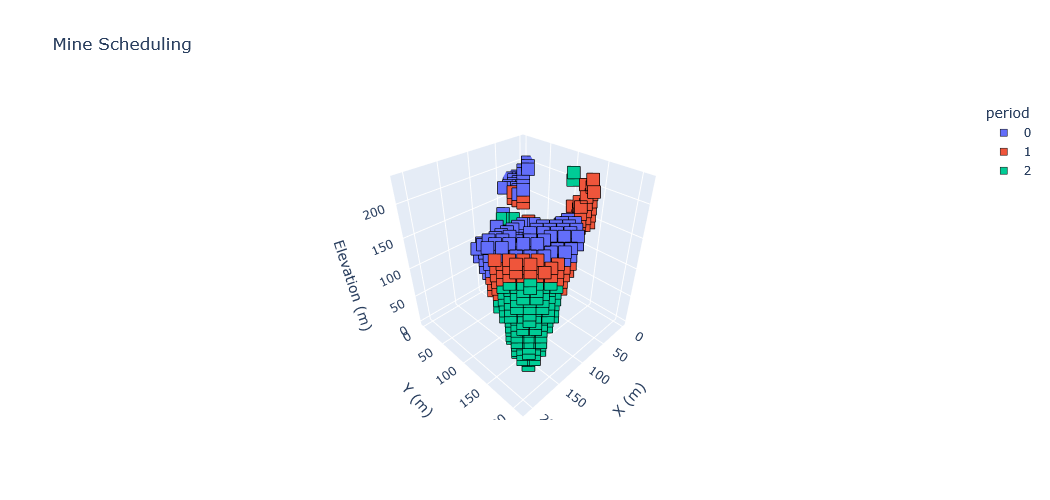

In [8]:
# Block dimensions
dx, dy, dz = 10, 10, 10

# Filter extracted blocks and prepare data
d = blocks.loc[blocks.period.notna()].copy()
d["period"] = d["period"].astype(int)
d[["x","y","z"]] *= [dx, dy, dz]
d["period"] -= d["period"].min()
d["period"] = d["period"].astype(str)

# Axis scaling for correct proportions
r = d[["x","y","z"]].max() - d[["x","y","z"]].min()
s = r.max()

# 3D categorical scatter with Plotly default colors
fig = px.scatter_3d(d, x="x", y="y", z="z", color="period", color_discrete_sequence=px.colors.qualitative.Plotly,
    category_orders={"period": sorted(d["period"], key=int)}, labels={"color": "Periods"}, 
    title="Mine Scheduling", width=900, height=500).update_traces(marker=dict(symbol="square", size=7, 
    line=dict(width=0.5, color="black"))).update_layout(scene=dict(xaxis_title="X (m)", yaxis_title="Y (m)", 
    zaxis_title="Elevation (m)", aspectmode="manual", aspectratio=dict(x=r.x/s, y=r.y/s, z=r.z/s)))
fig.show()

In [9]:
# Save 3D plot
fig.write_html("newman1_plot_cbc.html", full_html=True, include_plotlyjs="cdn",
    config={"responsive": True}, default_width="100vw", default_height="100vh")

### Capacity & Grade Chart

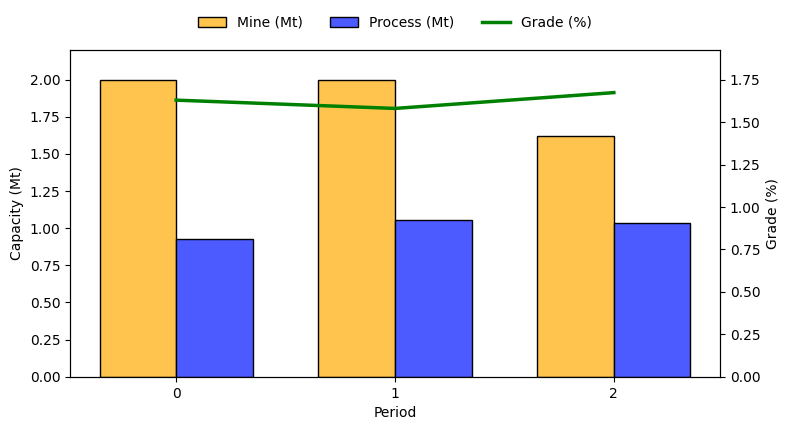

In [10]:
# Consider only extracted blocks
df = blocks.dropna(subset=["period"]).copy()

# Processed material only (destination == 1)
df["tonns_proc"]  = df["tonns"] * df["destination"]        # processed tonnage
df["grade_proc"] = df["grade"] * df["tonns_proc"]             # contained metal

# Aggregate by period
summary = (df.groupby("period", as_index=False).agg(ton_mine=("tonns", "sum"), ton_plant=("tonns_proc", "sum"), metal=("grade_proc", "sum")))

# Weighted average feed grade
summary["grade_avg"] = summary["metal"] / summary["ton_plant"]
summary["grade_avg"] = summary["grade_avg"].fillna(0)

# Plot
x = np.arange(len(summary))
w = 0.35
fig, ax1 = plt.subplots(figsize=(8, 4))

# Bars: Mine vs Process capacity (Mt)
ax1.bar(x - w/2, summary["ton_mine"] / 1e6, w, label="Mine (Mt)", color="#FFC44D", edgecolor="black")
ax1.bar(x + w/2, summary["ton_plant"] / 1e6, w, label="Process (Mt)", color="#4C5BFF", edgecolor="black")

ax1.set_xlabel("Period")
ax1.set_ylabel("Capacity (Mt)")
ax1.set_xticks(x)
ax1.set_xticklabels(summary["period"].astype(int))

# Y-axis from zero to slightly above max
ax1.set_ylim(0, 1.1 * max(summary["ton_mine"].max(), summary["ton_plant"].max()) / 1e6)

# Secondary axis: Feed grade
ax2 = ax1.twinx()
ax2.plot(x, summary["grade_avg"], color="green", linewidth=2.5, label="Grade (%)")

ax2.set_ylabel("Grade (%)")
ax2.set_ylim(0, 1.15 * summary["grade_avg"].max())

# Visual hierarchy
ax1.patch.set_visible(False)

# Legend
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)

plt.tight_layout()
plt.show()

In [11]:
# Save plot
fig.savefig("newman1_results_cbc.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# MIP Complete (LP Relaxed Solution)

In [12]:
import time
import pandas as pd
from mip import Model, MAXIMIZE, CONTINUOUS, xsum, OptimizationStatus

# =========================
# Solver
# =========================
solver_name = "CBC"  # added: CBC only
print(f"Using {solver_name} solver")

# =========================
# Data preparation
# =========================
ids = blocks["id"].tolist()
v = blocks["blockvalue"].tolist()
w = blocks["tonns"].tolist()
d = blocks["destination"].tolist()

n_blocks = len(ids)
id_to_idx = {bid: i for i, bid in enumerate(ids)}

# =========================
# Multi-period LP Relaxation
# =========================
code_start = time.time()
model = Model(sense=MAXIMIZE, solver_name=solver_name)
model.max_seconds = 3600
model.verbose = 1

# Continuous variables (0 <= x <= 1)
x = [[model.add_var(var_type=CONTINUOUS, lb=0.0, ub=1.0, name=f"x_{b}_{t}")
      for t in range(max_period)] for b in range(n_blocks)]

# Objective: maximize NPV
model.objective = xsum(
    (v[b] / ((1 + alpha) ** t)) * x[b][t]
    for b in range(n_blocks)
    for t in range(max_period)
)

# Each block is extracted at most once
for b in range(n_blocks):
    model += xsum(x[b][t] for t in range(max_period)) <= 1

# Precedence (cumulative form)
for bid in ids:
    if bid in precedence:
        b = id_to_idx[bid]
        for prec in precedence[bid]:
            if prec in id_to_idx:
                p = id_to_idx[prec]
                for t in range(max_period):
                    model += (
                        xsum(x[b][tau] for tau in range(t + 1))
                        <= xsum(x[p][tau] for tau in range(t + 1))
                    )

# Maximum capacities per period
for t in range(max_period):
    model += xsum(w[b] * x[b][t] for b in range(n_blocks)) <= MC_max
    model += xsum(d[b] * w[b] * x[b][t] for b in range(n_blocks)) <= PC_max

# =========================
# Solve
# =========================
print("Starting multi-period LP relaxation...")
opt_start = time.time()
with solver_log("newman1_cbc_cpit_relaxed.log"):  # added: CBC log
    status = model.optimize()
opt_time = time.time() - opt_start

# =========================
# Results
# =========================
if status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE):
    npv = model.objective_value
    print(f"\nStatus: {status}")
    print(f"NPV: {npv:,.0f}")
    print(f"Optimization time: {opt_time/60:.2f} minutes")

    blocks["period"] = -1
    blocks["x_value"] = 0.0
    total_extracted_frac = 0.0

    for b in range(n_blocks):
        for t in range(max_period):
            val = x[b][t].x
            if val is not None and val > 1e-6:
                blocks.loc[blocks["id"] == ids[b], "period"] = t
                blocks.loc[blocks["id"] == ids[b], "x_value"] = val
                total_extracted_frac += val
                break

    print(f"Total blocks (fractional sum): {total_extracted_frac:.2f}")
    print(f"Total blocks with x > 0.5: {(blocks['x_value'] > 0.5).sum()}")

    print("\nExtraction summary per period:")
    for t in range(max_period):
        frac_ton = sum(w[b] * (x[b][t].x or 0) for b in range(n_blocks))
        frac_proc = sum(d[b] * w[b] * (x[b][t].x or 0) for b in range(n_blocks))
        count = sum(1 for b in range(n_blocks) if (x[b][t].x or 0) > 1e-6)
        print(f"  Period {t}: {count:4d} blocks | {frac_ton:10,.0f} t mined | {frac_proc:10,.0f} t processed")
else:
    print(f"No feasible solution found. Status: {status}")

print(f"\nTotal code time: {(time.time() - code_start)/60:.2f} minutes")

blocks.to_csv("newman1_lp_solution_cbc.csv", index=False)
print("Solution saved.")

Using CBC solver
Starting multi-period LP relaxation...
(no solver output captured in newman1_cbc_cpit_relaxed.log)

Status: OptimizationStatus.OPTIMAL
NPV: 24,486,184
Optimization time: 0.03 minutes
Total blocks (fractional sum): 491.34
Total blocks with x > 0.5: 187

Extraction summary per period:
  Period 0:  945 blocks |  2,000,000 t mined |  1,100,000 t processed
  Period 1:  916 blocks |  2,000,000 t mined |  1,014,860 t processed
  Period 2:  954 blocks |  1,616,012 t mined |    904,485 t processed
  Period 3:    0 blocks |          0 t mined |          0 t processed
  Period 4:    0 blocks |          0 t mined |          0 t processed
  Period 5:    0 blocks |          0 t mined |          0 t processed

Total code time: 0.04 minutes
Solution saved.


In [13]:
# added: store results
res_lp = store_full("newman1_cbc_cpit_relaxed.log", relax=True)

# MIP Complete, MIP gap 1e-4

In [14]:
import time
import pandas as pd
from mip import Model, MAXIMIZE, BINARY, xsum, OptimizationStatus

# =========================
# Solver
# =========================
solver_name = "CBC"  # added: CBC only
print(f"Using {solver_name} solver")

# =========================
# Data preparation
# =========================
ids = blocks["id"].tolist()
v = blocks["blockvalue"].tolist()
w = blocks["tonns"].tolist()
d = blocks["destination"].tolist()

n_blocks = len(ids)
id_to_idx = {bid: i for i, bid in enumerate(ids)}

# =========================
# Multi-period MIP (integer)
# =========================
code_start = time.time()
model = Model(sense=MAXIMIZE, solver_name=solver_name)
model.max_seconds = 3600          # 1 hour (adjust if needed)
model.max_mip_gap = 1e-4           # added: relative MIP gap
model.verbose = 1

# Binary variables
x = [[model.add_var(var_type=BINARY, name=f"x_{b}_{t}")
      for t in range(max_period)] for b in range(n_blocks)]

# Objective: maximize NPV
model.objective = xsum(
    (v[b] / ((1 + alpha) ** t)) * x[b][t]
    for b in range(n_blocks)
    for t in range(max_period)
)

# 1. Each block is extracted at most once
for b in range(n_blocks):
    model += xsum(x[b][t] for t in range(max_period)) <= 1

# 2. Precedence (cumulative form)
for bid in ids:
    if bid in precedence:
        b = id_to_idx[bid]
        for prec in precedence[bid]:
            if prec in id_to_idx:
                p = id_to_idx[prec]
                for t in range(max_period):
                    model += (
                        xsum(x[b][tau] for tau in range(t + 1))
                        <= xsum(x[p][tau] for tau in range(t + 1))
                    )

# 3. Maximum capacities per period
for t in range(max_period):
    model += xsum(w[b] * x[b][t] for b in range(n_blocks)) <= MC_max
    model += xsum(d[b] * w[b] * x[b][t] for b in range(n_blocks)) <= PC_max

# =========================
# Solve
# =========================
print("Starting multi-period MIP optimization...")
opt_start = time.time()
with solver_log("newman1_cbc_cpit_gap1e-4.log"):  # added: CBC log
    status = model.optimize()
opt_time = time.time() - opt_start

# =========================
# Results
# =========================
if status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE):
    npv = model.objective_value
    print(f"\nStatus: {status}")
    print(f"NPV: {npv:,.0f}")
    print(f"Optimization time: {opt_time/60:.2f} minutes")
    print(f"Gap: {model.gap*100:.4f}%" if model.gap is not None else "")

    # Assign periods to blocks
    blocks["period"] = -1
    extracted = 0

    for b in range(n_blocks):
        for t in range(max_period):
            if x[b][t].x is not None and x[b][t].x > 0.5:
                blocks.loc[blocks["id"] == ids[b], "period"] = t
                extracted += 1
                break

    print(f"Total blocks extracted: {extracted}")

    print("\nExtraction summary per period:")
    for t in range(max_period):
        count = sum(1 for b in range(n_blocks) if x[b][t].x is not None and x[b][t].x > 0.5)
        tonnage = sum(w[b] for b in range(n_blocks) if x[b][t].x is not None and x[b][t].x > 0.5)
        process_ton = sum(d[b] * w[b] for b in range(n_blocks) if x[b][t].x is not None and x[b][t].x > 0.5)
        
        print(f"  Period {t}: {count:4d} blocks | {tonnage:10,.0f} t mined | {process_ton:10,.0f} t processed")
else:
    print(f"No feasible solution found. Status: {status}")

print(f"\nTotal code time: {(time.time() - code_start)/60:.2f} minutes")

# Save solution
blocks.to_csv("newman1_mip_solution_gap1e-4_cbc.csv", index=False)
print("Solution saved to newman1_mip_solution_gap1e-4_cbc.csv")

Using CBC solver
Starting multi-period MIP optimization...
(no solver output captured in newman1_cbc_cpit_gap1e-4.log)

Status: OptimizationStatus.FEASIBLE
NPV: 24,093,746
Optimization time: 60.02 minutes
Gap: 0.4803%
Total blocks extracted: 1059

Extraction summary per period:
  Period 0:  409 blocks |  1,998,461 t mined |    985,227 t processed
  Period 1:  358 blocks |  1,967,522 t mined |    966,521 t processed
  Period 2:  292 blocks |  1,650,029 t mined |  1,067,597 t processed
  Period 3:    0 blocks |          0 t mined |          0 t processed
  Period 4:    0 blocks |          0 t mined |          0 t processed
  Period 5:    0 blocks |          0 t mined |          0 t processed

Total code time: 60.03 minutes
Solution saved to newman1_mip_solution_gap1e-4_cbc.csv


In [15]:
# added: store results
res_g4 = store_full("newman1_cbc_cpit_gap1e-4.log", relax=False)

# MIP Complete, MIP gap 1e-6

In [16]:
import time
import pandas as pd
from mip import Model, MAXIMIZE, BINARY, xsum, OptimizationStatus

# =========================
# Solver
# =========================
solver_name = "CBC"  # added: CBC only
print(f"Using {solver_name} solver")

# =========================
# Data preparation
# =========================
ids = blocks["id"].tolist()
v = blocks["blockvalue"].tolist()
w = blocks["tonns"].tolist()
d = blocks["destination"].tolist()

n_blocks = len(ids)
id_to_idx = {bid: i for i, bid in enumerate(ids)}

# =========================
# Multi-period MIP (integer)
# =========================
code_start = time.time()
model = Model(sense=MAXIMIZE, solver_name=solver_name)
model.max_seconds = 3600          # 1 hour (adjust if needed)
model.max_mip_gap = 1e-6           # added: relative MIP gap
model.verbose = 1

# Binary variables
x = [[model.add_var(var_type=BINARY, name=f"x_{b}_{t}")
      for t in range(max_period)] for b in range(n_blocks)]

# Objective: maximize NPV
model.objective = xsum(
    (v[b] / ((1 + alpha) ** t)) * x[b][t]
    for b in range(n_blocks)
    for t in range(max_period)
)

# 1. Each block is extracted at most once
for b in range(n_blocks):
    model += xsum(x[b][t] for t in range(max_period)) <= 1

# 2. Precedence (cumulative form)
for bid in ids:
    if bid in precedence:
        b = id_to_idx[bid]
        for prec in precedence[bid]:
            if prec in id_to_idx:
                p = id_to_idx[prec]
                for t in range(max_period):
                    model += (
                        xsum(x[b][tau] for tau in range(t + 1))
                        <= xsum(x[p][tau] for tau in range(t + 1))
                    )

# 3. Maximum capacities per period
for t in range(max_period):
    model += xsum(w[b] * x[b][t] for b in range(n_blocks)) <= MC_max
    model += xsum(d[b] * w[b] * x[b][t] for b in range(n_blocks)) <= PC_max

# =========================
# Solve
# =========================
print("Starting multi-period MIP optimization...")
opt_start = time.time()
with solver_log("newman1_cbc_cpit_gap1e-6.log"):  # added: CBC log
    status = model.optimize()
opt_time = time.time() - opt_start

# =========================
# Results
# =========================
if status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE):
    npv = model.objective_value
    print(f"\nStatus: {status}")
    print(f"NPV: {npv:,.0f}")
    print(f"Optimization time: {opt_time/60:.2f} minutes")
    print(f"Gap: {model.gap*100:.4f}%" if model.gap is not None else "")

    # Assign periods to blocks
    blocks["period"] = -1
    extracted = 0

    for b in range(n_blocks):
        for t in range(max_period):
            if x[b][t].x is not None and x[b][t].x > 0.5:
                blocks.loc[blocks["id"] == ids[b], "period"] = t
                extracted += 1
                break

    print(f"Total blocks extracted: {extracted}")

    print("\nExtraction summary per period:")
    for t in range(max_period):
        count = sum(1 for b in range(n_blocks) if x[b][t].x is not None and x[b][t].x > 0.5)
        tonnage = sum(w[b] for b in range(n_blocks) if x[b][t].x is not None and x[b][t].x > 0.5)
        process_ton = sum(d[b] * w[b] for b in range(n_blocks) if x[b][t].x is not None and x[b][t].x > 0.5)
        
        print(f"  Period {t}: {count:4d} blocks | {tonnage:10,.0f} t mined | {process_ton:10,.0f} t processed")
else:
    print(f"No feasible solution found. Status: {status}")

print(f"\nTotal code time: {(time.time() - code_start)/60:.2f} minutes")

# Save solution
blocks.to_csv("newman1_mip_solution_gap1e-6_cbc.csv", index=False)
print("Solution saved to newman1_mip_solution_gap1e-6_cbc.csv")

Using CBC solver
Starting multi-period MIP optimization...
(no solver output captured in newman1_cbc_cpit_gap1e-6.log)

Status: OptimizationStatus.FEASIBLE
NPV: 24,093,746
Optimization time: 60.02 minutes
Gap: 0.3763%
Total blocks extracted: 1059

Extraction summary per period:
  Period 0:  409 blocks |  1,998,461 t mined |    985,227 t processed
  Period 1:  358 blocks |  1,967,522 t mined |    966,521 t processed
  Period 2:  292 blocks |  1,650,029 t mined |  1,067,597 t processed
  Period 3:    0 blocks |          0 t mined |          0 t processed
  Period 4:    0 blocks |          0 t mined |          0 t processed
  Period 5:    0 blocks |          0 t mined |          0 t processed

Total code time: 60.03 minutes
Solution saved to newman1_mip_solution_gap1e-6_cbc.csv


In [17]:
# added: store results
res_g6 = store_full("newman1_cbc_cpit_gap1e-6.log", relax=False)

# Comparison: SD-CPIT x CPIT LP (UB) x CPIT gap 1e-4 x CPIT gap 1e-6

In [18]:
# added: Comparison SD-CPIT x CPIT LP (UB) x CPIT gap 1e-4 x CPIT gap 1e-6
T = max(len(res_lp["discounted"]), len(res_g4["discounted"]), len(res_g6["discounted"]), len(res_seq["time"]))
pad = lambda lst, fill: list(lst) + [fill] * (T - len(lst))
ub = res_lp["npv"]

# Discounted value per period (the CPIT models solve all periods at once, so only SD-CPIT has time per period)
per_period = pd.DataFrame({
    "Period": [str(t) for t in range(T)],
    "SD-CPIT": pad(res_seq["discounted"], 0.0),
    "CPIT LP (UB)": pad(res_lp["discounted"], 0.0),
    "CPIT gap 1e-4": pad(res_g4["discounted"], 0.0),
    "CPIT gap 1e-6": pad(res_g6["discounted"], 0.0),
    "SD-CPIT Opt Time (s)": pad(res_seq["time"], np.nan),
})
per_period.loc[len(per_period)] = ["NPV", res_seq["npv"], res_lp["npv"], res_g4["npv"], res_g6["npv"], res_seq["opt_time"]]

fmt_val = lambda val: "" if pd.isna(val) else f"{val:,.0f}"
fmt_s = lambda val: "" if pd.isna(val) else f"{val:.2f}"
print("Discounted value per period\n")
print(per_period.to_string(index=False, formatters={**{c: fmt_val for c in per_period.columns[1:5]}, "SD-CPIT Opt Time (s)": fmt_s}))

# Summary
summary = pd.DataFrame({
    "Method": ["SD-CPIT", "CPIT LP (UB)", "CPIT gap 1e-4", "CPIT gap 1e-6"],
    "NPV": [res_seq["npv"], res_lp["npv"], res_g4["npv"], res_g6["npv"]],
    "Gap to UB (%)": [100 * (ub - r["npv"]) / ub for r in (res_seq, res_lp, res_g4, res_g6)],
    "Solver bound": [np.nan, res_lp["bound"], res_g4["bound"], res_g6["bound"]],
    "Solver MIP gap (%)": [np.nan, 0.0, 100 * res_g4["mip_gap"], 100 * res_g6["mip_gap"]],
    "Opt Time (s)": [res_seq["opt_time"], res_lp["opt_time"], res_g4["opt_time"], res_g6["opt_time"]],
    "Solver log": [res_seq["log"], res_lp["log"], res_g4["log"], res_g6["log"]],
})
print("\nSummary\n")
print(summary.to_string(index=False, formatters={
    "NPV": fmt_val, "Solver bound": fmt_val, "Gap to UB (%)": lambda val: f"{val:.4f}",
    "Solver MIP gap (%)": lambda val: "" if pd.isna(val) else f"{val:.6f}", "Opt Time (s)": fmt_s}))

# Save comparison
per_period.to_csv("newman1_comparison_per_period_cbc.csv", index=False)
summary.to_csv("newman1_comparison_summary_cbc.csv", index=False)

Discounted value per period

Period    SD-CPIT CPIT LP (UB) CPIT gap 1e-4 CPIT gap 1e-6 SD-CPIT Opt Time (s)
     0  8,690,007   10,642,669     7,827,066     7,827,066                20.60
     1  7,719,664    8,134,792     8,259,521     8,259,521                 2.97
     2  7,767,194    5,708,723     8,007,159     8,007,159                 0.02
     3          0            0             0             0                 0.00
     4          0            0             0             0                  NaN
     5          0            0             0             0                  NaN
   NPV 24,176,865   24,486,184    24,093,746    24,093,746                23.60

Summary

       Method        NPV Gap to UB (%) Solver bound Solver MIP gap (%) Opt Time (s)                   Solver log
      SD-CPIT 24,176,865        1.2632          NaN                NaN        23.60       newman1_cbc_sdcpit.log
 CPIT LP (UB) 24,486,184        0.0000   24,486,184           0.000000         1.57 newman1_cbc